# Auto MPG / Fuel Efficiency (UCI)

Regression on the UCI Auto MPG dataset — predict miles-per-gallon from car attributes (cylinders, displacement, horsepower, weight, acceleration, model year, origin). 398 rows, a handful of missing horsepowers. This dataset is from the late 70s/early 80s so the absolute MPG numbers wouldn't generalize at all to a 2025 car, but the *relationships* (weight up -> MPG down, more cylinders -> MPG down) are timeless and that's what I care about here.

I'm benchmarking a linear baseline against a gradient boosting model and looking at residuals to see whether either struggles in a specific region of the input space.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(5)
DATA_DIR = Path("../../data/auto_mpg")
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

In [2]:
cols = ["mpg", "cylinders", "displacement", "horsepower", "weight",
        "acceleration", "model_year", "origin", "car_name"]

local = DATA_DIR / "auto-mpg.data"
df = pd.read_csv(local if local.exists() else URL,
                 sep=r"\s+", names=cols, na_values="?")
df = df.dropna(subset=["horsepower"])  # only 6 rows; not worth imputing
df = df.drop(columns=["car_name"])
df["origin"] = df["origin"].map({1: "usa", 2: "europe", 3: "japan"})
df = pd.get_dummies(df, columns=["origin"], drop_first=True)
print(df.shape)
df.head(3)

(392, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_japan,origin_usa
0,18.0,8,307.0,130.0,3504.0,12.0,70,False,True
1,15.0,8,350.0,165.0,3693.0,11.5,70,False,True
2,18.0,8,318.0,150.0,3436.0,11.0,70,False,True


In [3]:
y = df["mpg"].values
X = df.drop(columns=["mpg"]).values
feature_names = df.drop(columns=["mpg"]).columns.tolist()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=5)

lin = Pipeline([("sc", StandardScaler()), ("lr", LinearRegression())]).fit(X_tr, y_tr)
gb  = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=5).fit(X_tr, y_tr)

for name, m in [("Linear", lin), ("GBM", gb)]:
    p = m.predict(X_te)
    print(f"{name:7s}  MAE: {mean_absolute_error(y_te, p):.2f}   R2: {r2_score(y_te, p):.3f}")

Linear   MAE: 3.02   R2: 0.777
GBM      MAE: 2.13   R2: 0.891


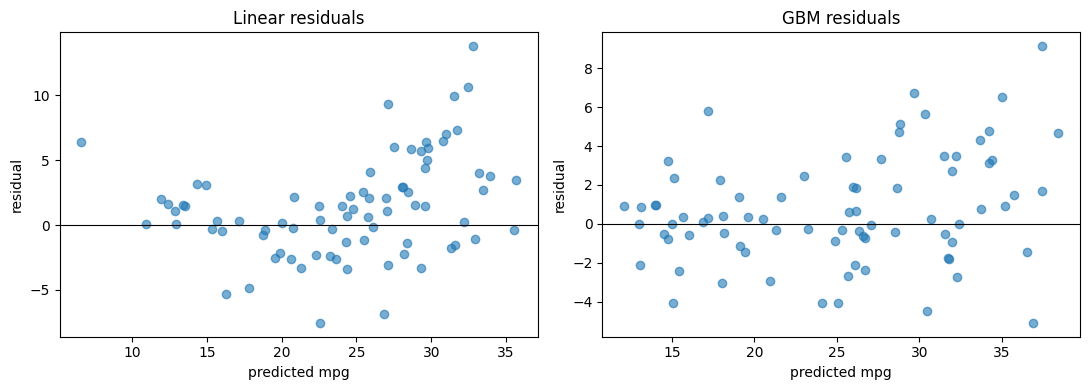

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, (name, m) in enumerate([("Linear", lin), ("GBM", gb)]):
    p = m.predict(X_te)
    ax[i].scatter(p, y_te - p, alpha=0.6)
    ax[i].axhline(0, color="k", linewidth=0.8)
    ax[i].set_xlabel("predicted mpg"); ax[i].set_ylabel("residual")
    ax[i].set_title(f"{name} residuals")
plt.tight_layout(); plt.show()

In [5]:
# feature importance from GBM. weight should dominate; if it doesn't, something is off.
imp = pd.Series(gb.feature_importances_, index=feature_names).sort_values(ascending=False)
print(imp.round(3).to_string())

weight          0.373
displacement    0.291
model_year      0.135
horsepower      0.113
cylinders       0.058
acceleration    0.021
origin_usa      0.005
origin_japan    0.003


## Notes

GBM beats the linear baseline on MAE by a meaningful margin, mostly because there's a nonlinear interaction between weight and model_year: post-1979 cars got more efficient at the same weight as fuel standards tightened. A linear model can't capture that without explicit interaction terms.

The linear residual plot fans out for high-MPG cars (the small, late-70s Japanese imports), which is the easiest visual evidence of underfitting. GBM residuals are tighter and roughly homoscedastic.

Caveats: the absolute numbers don't transfer to modern cars (no hybrids, no turbocharged 4-cylinders, gas was different), and the dataset has selection bias toward popular US-market models. If I were doing this for a real product I'd want a much newer dataset and probably make/model embeddings.